<a href="https://colab.research.google.com/github/xxanshixx/PROJECT/blob/main/Cancer_Classification_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **6.1 - Breast Cancer Prediction with TensorFlow / Keras (Binary Classification)**

**Dataset:** Breast Cancer Wisconsin — 30 numeric features,
predict whether a tumor is *malignant* or *benign*.

**The pipeline we'll establish here is the template for every project in this section:**
load → explore → split → scale → build → train → evaluate.

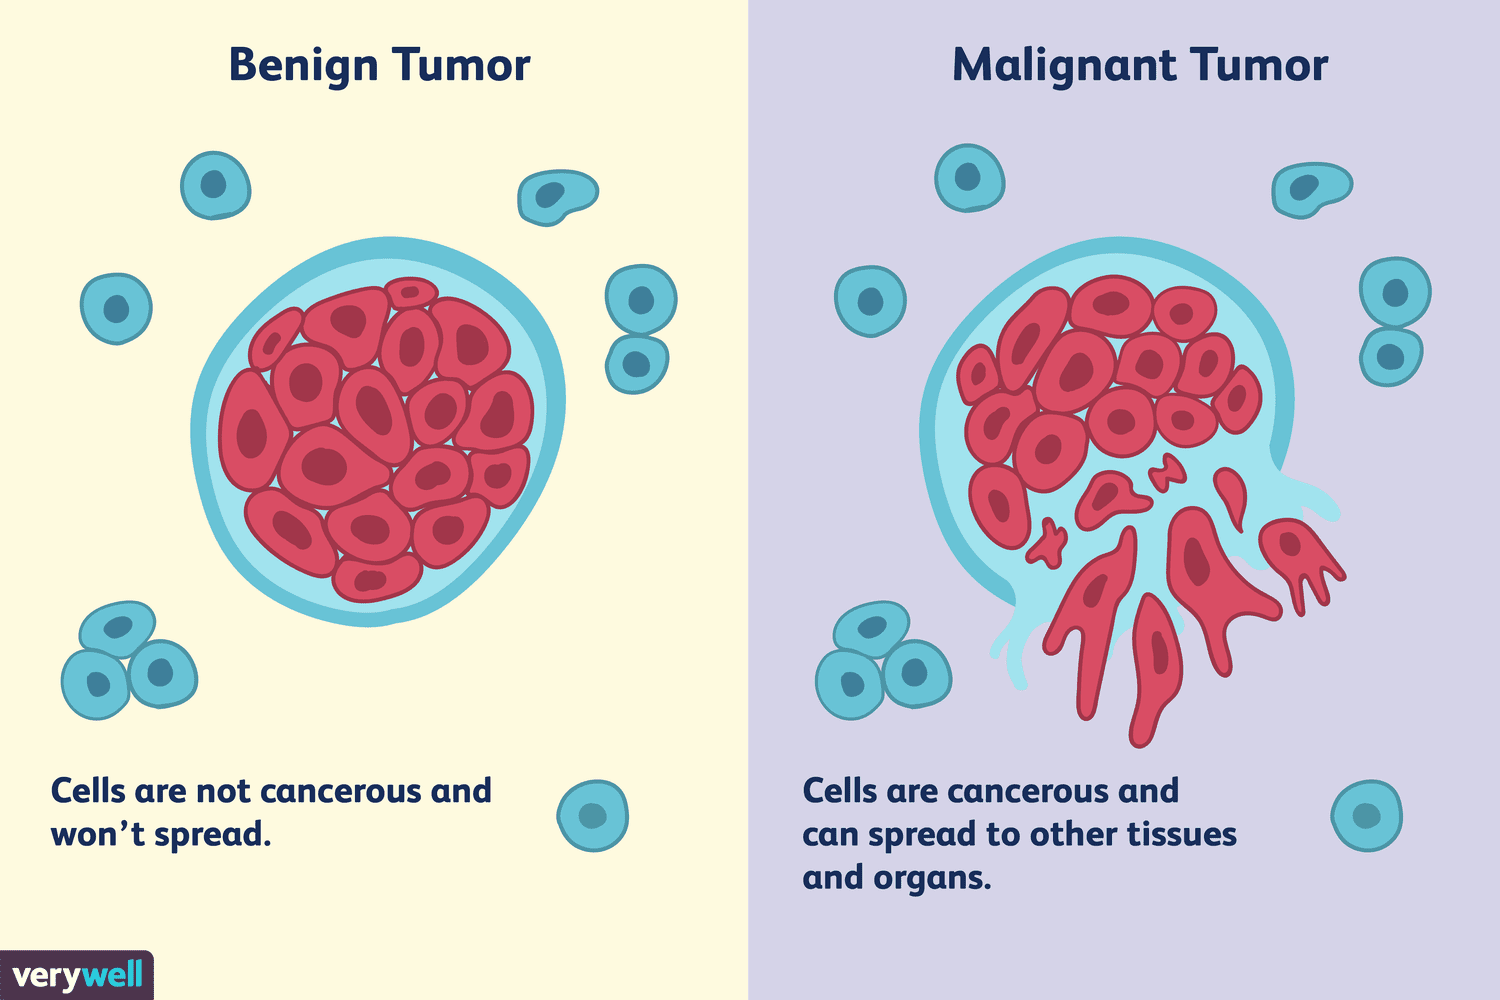

## **1. Imports & Setup**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [3]:
# set seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

# configurations
pd.set_option('display.max_columns', None)                          # show all columns, don't truncate
pd.set_option('display.float_format', lambda x: f'{x:.4f}')         # no scientific notation, 4 decimals
np.set_printoptions(suppress=True)                                  # no scientific notation for numpy arrays

## **2. Load the data**

In [4]:
# upload the dataset file and load it in a df
df = pd.read_csv("/content/breast_cancer_dataset.csv")

## **3. Quick Exploration**

In [5]:
df.shape

(569, 33)

In [6]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,NaN
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,NaN
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,NaN
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,NaN
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,NaN


In [7]:
# drop "id" and "Unnamed: 32" colummns
df = df.drop(columns=["id", "Unnamed: 32"])

In [8]:
# convert labels to 1 and 0
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1}).astype(int)

In [9]:
class_names = ["benign", "malignant"]

In [10]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,1,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,1,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,1,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [11]:
df.shape

(569, 31)

In [12]:
# check target distribution
df["diagnosis"].value_counts()
# reasonably balanced, slightly skewed

,count
diagnosis,
0,357
1,212


In [13]:
df["diagnosis"].value_counts(normalize=True)*100

,proportion
diagnosis,
0,62.7417
1,37.2583


In [35]:
# descriptive stats for specific columns
df[["diagnosis","radius_mean","texture_mean","perimeter_mean","area_mean","smoothness_mean","compactness_mean","symmetry_mean"]].describe()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,symmetry_mean
count,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000
mean,0.3726,14.1273,19.2896,91.9690,654.8891,0.0964,0.1043,0.1812
std,0.4839,3.5240,4.3010,24.2990,351.9141,0.0141,0.0528,0.0274
min,0.0000,6.9810,9.7100,43.7900,143.5000,0.0526,0.0194,0.1060
25%,0.0000,11.7000,16.1700,75.1700,420.3000,0.0864,0.0649,0.1619
50%,0.0000,13.3700,18.8400,86.2400,551.1000,0.0959,0.0926,0.1792
75%,1.0000,15.7800,21.8000,104.1000,782.7000,0.1053,0.1304,0.1957
max,1.0000,28.1100,39.2800,188.5000,2501.0000,0.1634,0.3454,0.3040


## **4. Train/Val/Test Split**

In [15]:
# split the df into features (X) and target (y)
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [16]:
X.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [17]:
y.head()

,diagnosis
0,1
1,1
2,1
3,1
4,1


In [18]:
# first peel off the test set (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# then split the rest (X_train_full) into train (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=42
)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)

Train: (341, 30)
Val:   (114, 30)
Test:  (114, 30)


## **5. Scale the features**

\begin{equation}
z = \frac{x - \mu}{\sigma}
\end{equation}


>Note: Fit scaler on train only - scaling before splitting leaks test-set mean/std into training (data leakage).

In [19]:
scaler = StandardScaler()

In [20]:
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

>Note: transform (not fit_transform) on val/test — they must be scaled with the train set's mean/std; refitting would give each set its own scaling, breaking comparability and leaking their statistics.

## **6. Build the model**

A small fully-connected network:
- **ReLU** in the hidden layers (the workhorse activation from Section 5)
- **sigmoid** on the output - it squashes to a value in (0, 1) we read as
  *"probability of malignant"* (our positive class), which is exactly what
  binary classification needs.

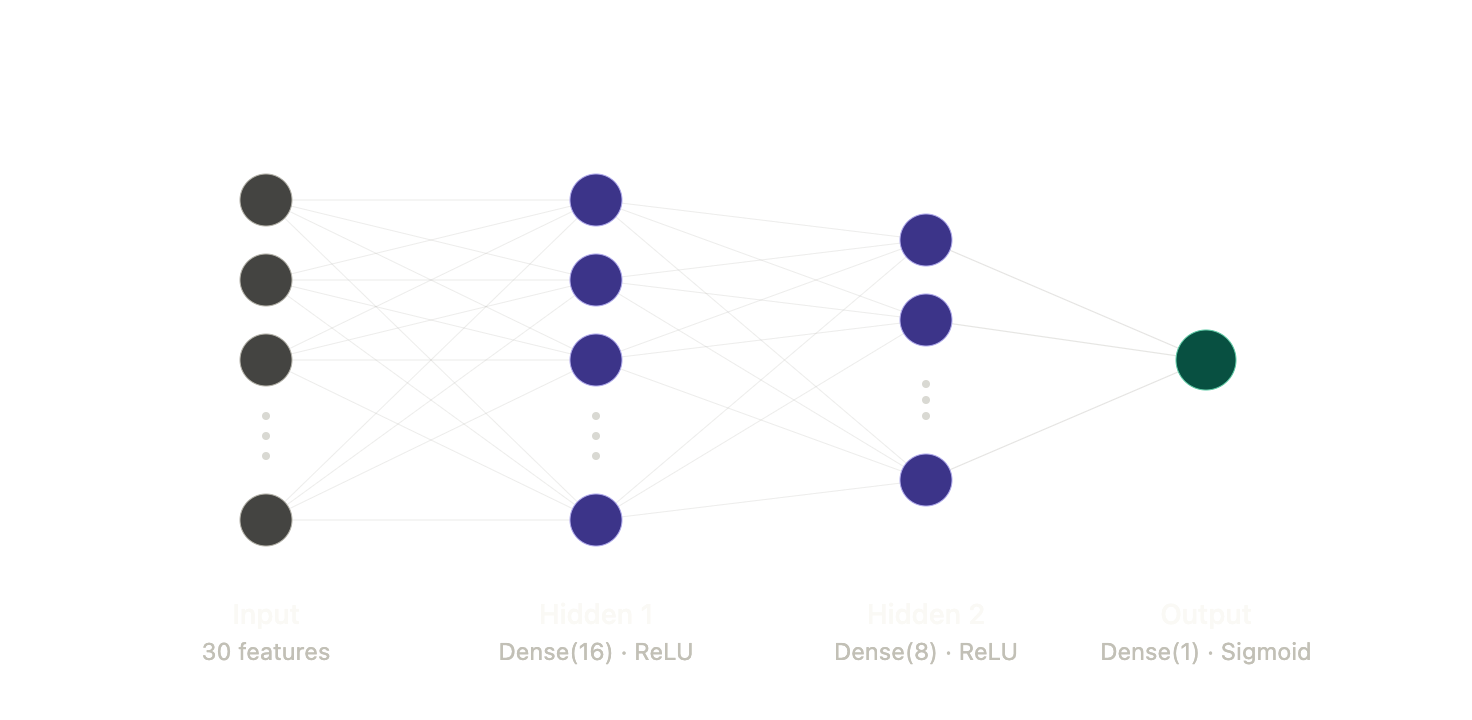

In [21]:
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),     # 30 features in
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")   # 1 probability out
])

In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## **7. Training**

**Early stopping** watches the validation loss and halts when it stops improving,
then restores the best weights. This is our first line of defense against overfitting.

In [24]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

In [25]:
class PrintEvery10(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs):
        if (epoch + 1) % 10 == 0:
            print(f"epoch {epoch + 1:3d}  "
                  f"loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}  "
                  f"val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")

In [26]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, PrintEvery10()],
    verbose=0
)

epoch  10  loss 0.2241  acc 0.9589  val_loss 0.2192  val_acc 0.9737
epoch  20  loss 0.0935  acc 0.9707  val_loss 0.1105  val_acc 0.9649
epoch  30  loss 0.0668  acc 0.9795  val_loss 0.0908  val_acc 0.9649
epoch  40  loss 0.0532  acc 0.9824  val_loss 0.0858  val_acc 0.9649
epoch  50  loss 0.0438  acc 0.9853  val_loss 0.0867  val_acc 0.9649


In [27]:
print("Trained for", len(history.history["loss"]))

Trained for 51


## **8. Learning Curves**

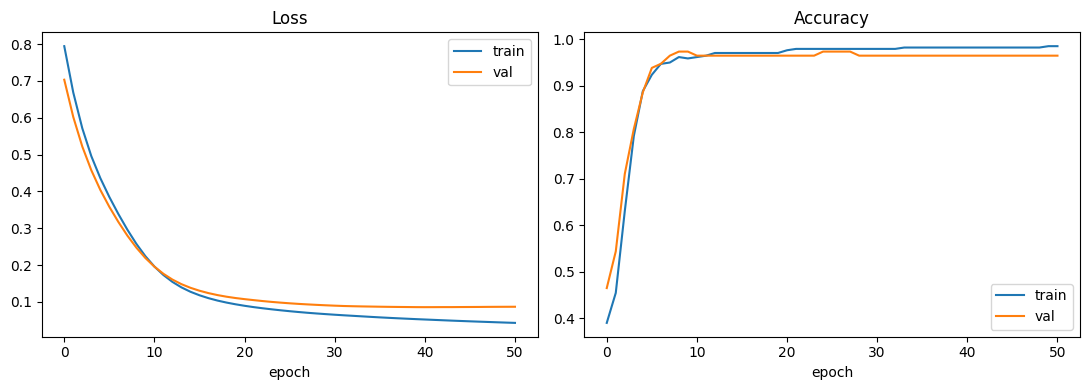

In [28]:
hist = history.history

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(hist["loss"], label="train")
plt.plot(hist["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist["accuracy"], label="train")
plt.plot(hist["val_accuracy"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.show()

## **9. Evaluate on the test set**

>Note: This is the first and only time we use the test set.

In [29]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 3))
print("Test accuracy:", round(test_acc, 3))

Test loss: 0.087
Test accuracy: 0.974


In [30]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("First 5 probabilities:", y_prob[:5].round(3))
print("First 5 predictions:  ", y_pred[:5])

First 5 probabilities: [0.001 1.    0.091 0.792 0.654]
First 5 predictions:   [0 1 0 1 1]


## **10. Confusion Matrix**

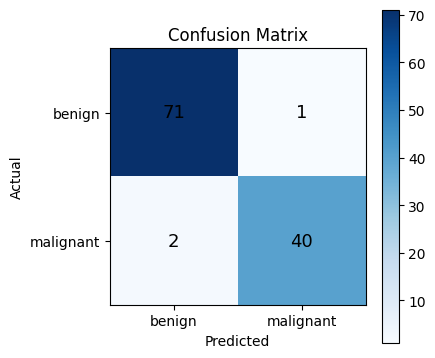

In [31]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks([0, 1], ["benign", "malignant"])
plt.yticks([0, 1], ["benign", "malignant"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
plt.colorbar()
plt.tight_layout()
plt.show()

## **11. Precision, recall, F1**

In [32]:
print(classification_report(y_test, y_pred, target_names = class_names))

              precision    recall  f1-score   support

      benign       0.97      0.99      0.98        72
   malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## **12. ROC curve & AUC**

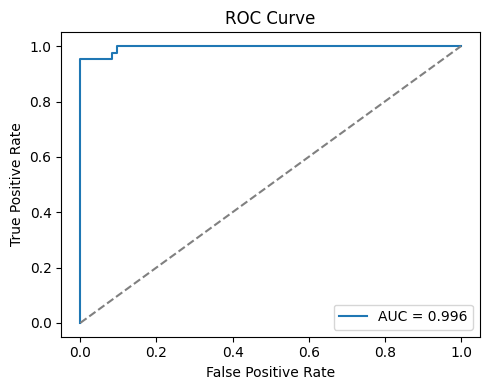

In [33]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.tight_layout()
plt.show()